<a href="https://colab.research.google.com/github/asilbek1301/fresh_scan/blob/main/freshscan.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **FreshScan 🍎 Fresh or Rotten Fruit Detector**

**DataSet 💠 Training (YOLOv8) 💠 Results 💠 Testing + Recommendation**

Upload a fruit photo → the model says if it is **fresh** or **rotten** → it recommends what to do with it.

> Before running: **Runtime → Change runtime type → T4 GPU**

In [3]:
print('FRESHSCAN AI MODEL')

FRESHSCAN AI MODEL


In [4]:
# --------------------------------
# Check GPU
# --------------------------------
# Must print True. If False: Runtime → Change runtime type → T4 GPU (training on CPU takes ~2 hours)

import torch
print('GPU available:', torch.cuda.is_available())
if torch.cuda.is_available():
    print('GPU name:', torch.cuda.get_device_name(0))

GPU available: True
GPU name: Tesla T4


# **1. Setup & Dataset**

In [6]:
# --------------------------------
# Mount Google Drive
# --------------------------------

from google.colab import drive
import os

drive.mount('/content/drive')

SAVE_DIR = '/content/drive/MyDrive/freshscan'      # trained model is saved here, so it survives after the Colab session ends
os.makedirs(SAVE_DIR, exist_ok=True)

Mounted at /content/drive


In [7]:
# --------------------------------
# Download Dataset from Kaggle
# --------------------------------
# If the download fails: search Kaggle for "fruits fresh and rotten for classification"
# and copy the "owner/name" part of the dataset URL here.
# If it asks you to log in: add KAGGLE_USERNAME and KAGGLE_KEY in Colab Secrets (🔑 icon on the left).

import kagglehub

path = kagglehub.dataset_download("sriramr/fruits-fresh-and-rotten-for-classification")
print('Downloaded to:', path)

Using Colab cache for faster access to the 'fruits-fresh-and-rotten-for-classification' dataset.
Downloaded to: /kaggle/input/fruits-fresh-and-rotten-for-classification


In [8]:
# --------------------------------
# Look at the folder tree
# --------------------------------

!find {path} -maxdepth 3 -type d

/kaggle/input/fruits-fresh-and-rotten-for-classification
/kaggle/input/fruits-fresh-and-rotten-for-classification/dataset
/kaggle/input/fruits-fresh-and-rotten-for-classification/dataset/dataset
/kaggle/input/fruits-fresh-and-rotten-for-classification/dataset/dataset/test
/kaggle/input/fruits-fresh-and-rotten-for-classification/dataset/dataset/train
/kaggle/input/fruits-fresh-and-rotten-for-classification/dataset/test
/kaggle/input/fruits-fresh-and-rotten-for-classification/dataset/test/rottenbanana
/kaggle/input/fruits-fresh-and-rotten-for-classification/dataset/test/freshoranges
/kaggle/input/fruits-fresh-and-rotten-for-classification/dataset/test/rottenoranges
/kaggle/input/fruits-fresh-and-rotten-for-classification/dataset/test/freshbanana
/kaggle/input/fruits-fresh-and-rotten-for-classification/dataset/test/rottenapples
/kaggle/input/fruits-fresh-and-rotten-for-classification/dataset/test/freshapples
/kaggle/input/fruits-fresh-and-rotten-for-classification/dataset/train
/kaggle/in

In [9]:
# --------------------------------
# Define Dataset Path
# --------------------------------
# DATA_DIR must be the folder that contains train/ and test/
# ⚠️ Change it if the tree above looks different

DATA_DIR = f'{path}/dataset'

print('train/ exists:', os.path.exists(f'{DATA_DIR}/train'))
print('test/  exists:', os.path.exists(f'{DATA_DIR}/test'))

train/ exists: True
test/  exists: True


In [10]:
# --------------------------------
# Check Classes
# --------------------------------

for split in ['train', 'test']:
    print(f'--- {split} ---')
    for cls in sorted(os.listdir(f'{DATA_DIR}/{split}')):
        print(f'{cls:20s}', len(os.listdir(f'{DATA_DIR}/{split}/{cls}')))       # how many images in each class

--- train ---
freshapples          1693
freshbanana          1581
freshoranges         1466
rottenapples         2342
rottenbanana         2224
rottenoranges        1595
--- test ---
freshapples          395
freshbanana          381
freshoranges         388
rottenapples         601
rottenbanana         530
rottenoranges        403


# **2. START TRAINING AI MODEL**

In [11]:
!pip install -q ultralytics

In [12]:
# --------------------------------
# Train YOLOv8 Classifier
# --------------------------------

from ultralytics import YOLO

model = YOLO('yolov8n-cls.pt')                      # pretrained model | n = nano (smallest, fastest) | cls = classification

model.train(
    data=DATA_DIR,                                  # train/ → training | test/ → used for validation after every epoch
    epochs=10,                                      # Epoch -- model reads the whole dataset from start to end
    imgsz=224,                                      # same image size as MobileNetV2
    batch=32,                                       # 32 images go into the model at once
    project=SAVE_DIR,
    name='yolo_cls',
    exist_ok=True                                   # overwrite the same folder instead of creating yolo_cls2, yolo_cls3...
)
# best epoch is saved automatically → SAVE_DIR/yolo_cls/weights/best.pt

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics 8.4.191 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/input/fruits-fresh-and-rotten-for-classification/dataset, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=10, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, 

ultralytics.utils.metrics.ClassifyMetrics object with attributes:

confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7af2f40188c0>
curves: []
curves_results: []
fitness: 1.0
keys: ['metrics/accuracy_top1', 'metrics/accuracy_top5']
results_dict: {'metrics/accuracy_top1': 1.0, 'metrics/accuracy_top5': 1.0, 'fitness': 1.0}
save_dir: PosixPath('/content/drive/MyDrive/freshscan/yolo_cls')
speed: {'preprocess': 0.12958563713900198, 'inference': 0.41862906189713267, 'loss': 0.00019988510032920581, 'postprocess': 0.00028173498879074086}
top1: 1.0
top5: 1.0

In [13]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# **3. Results**

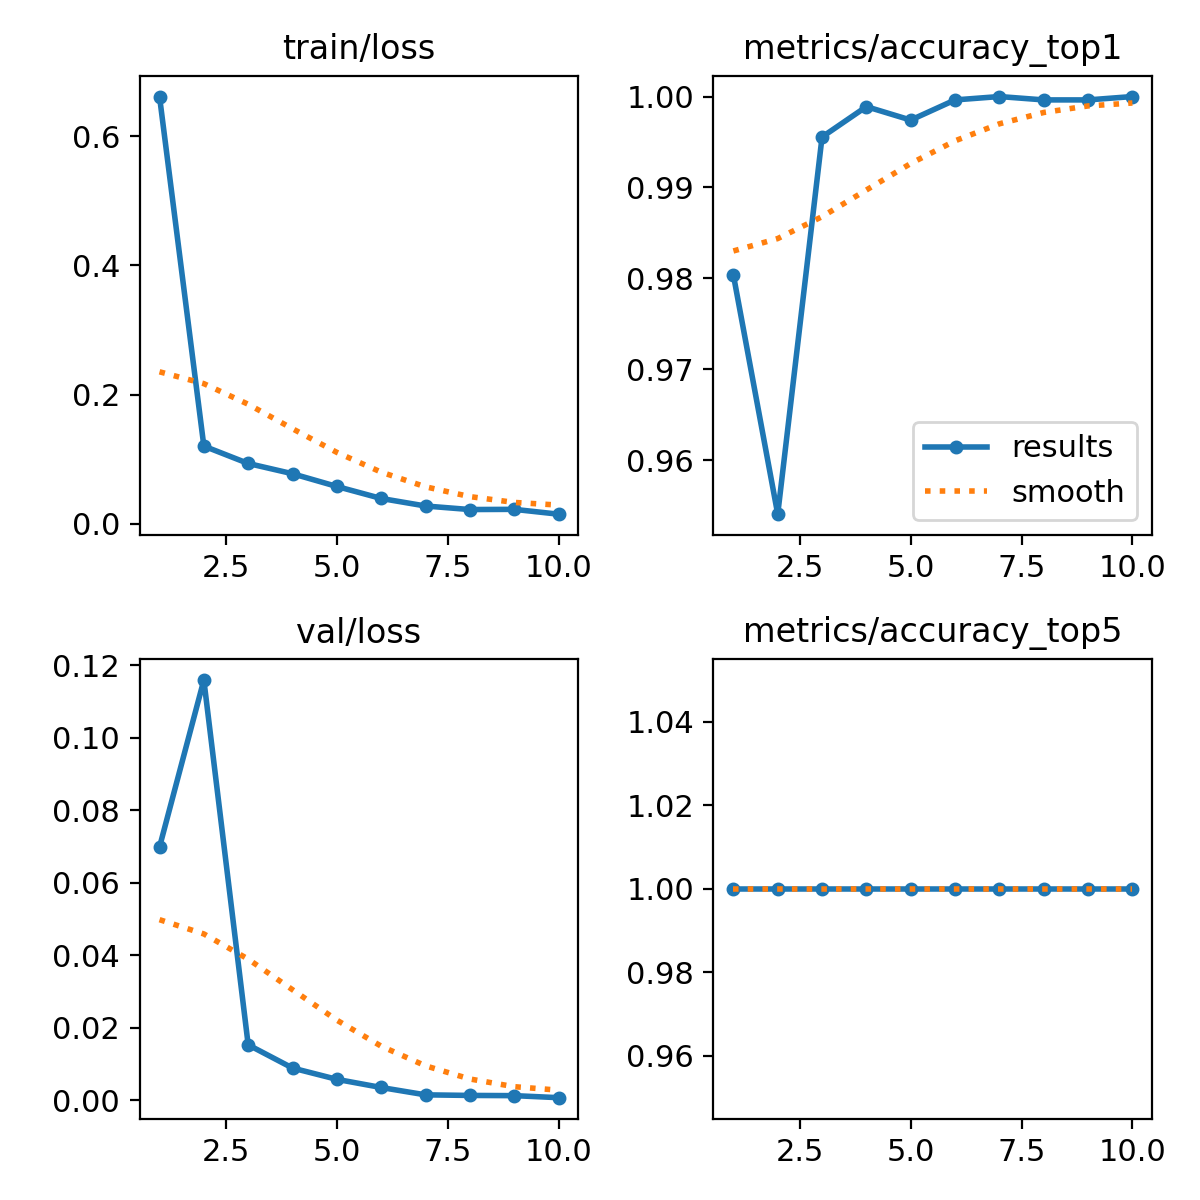

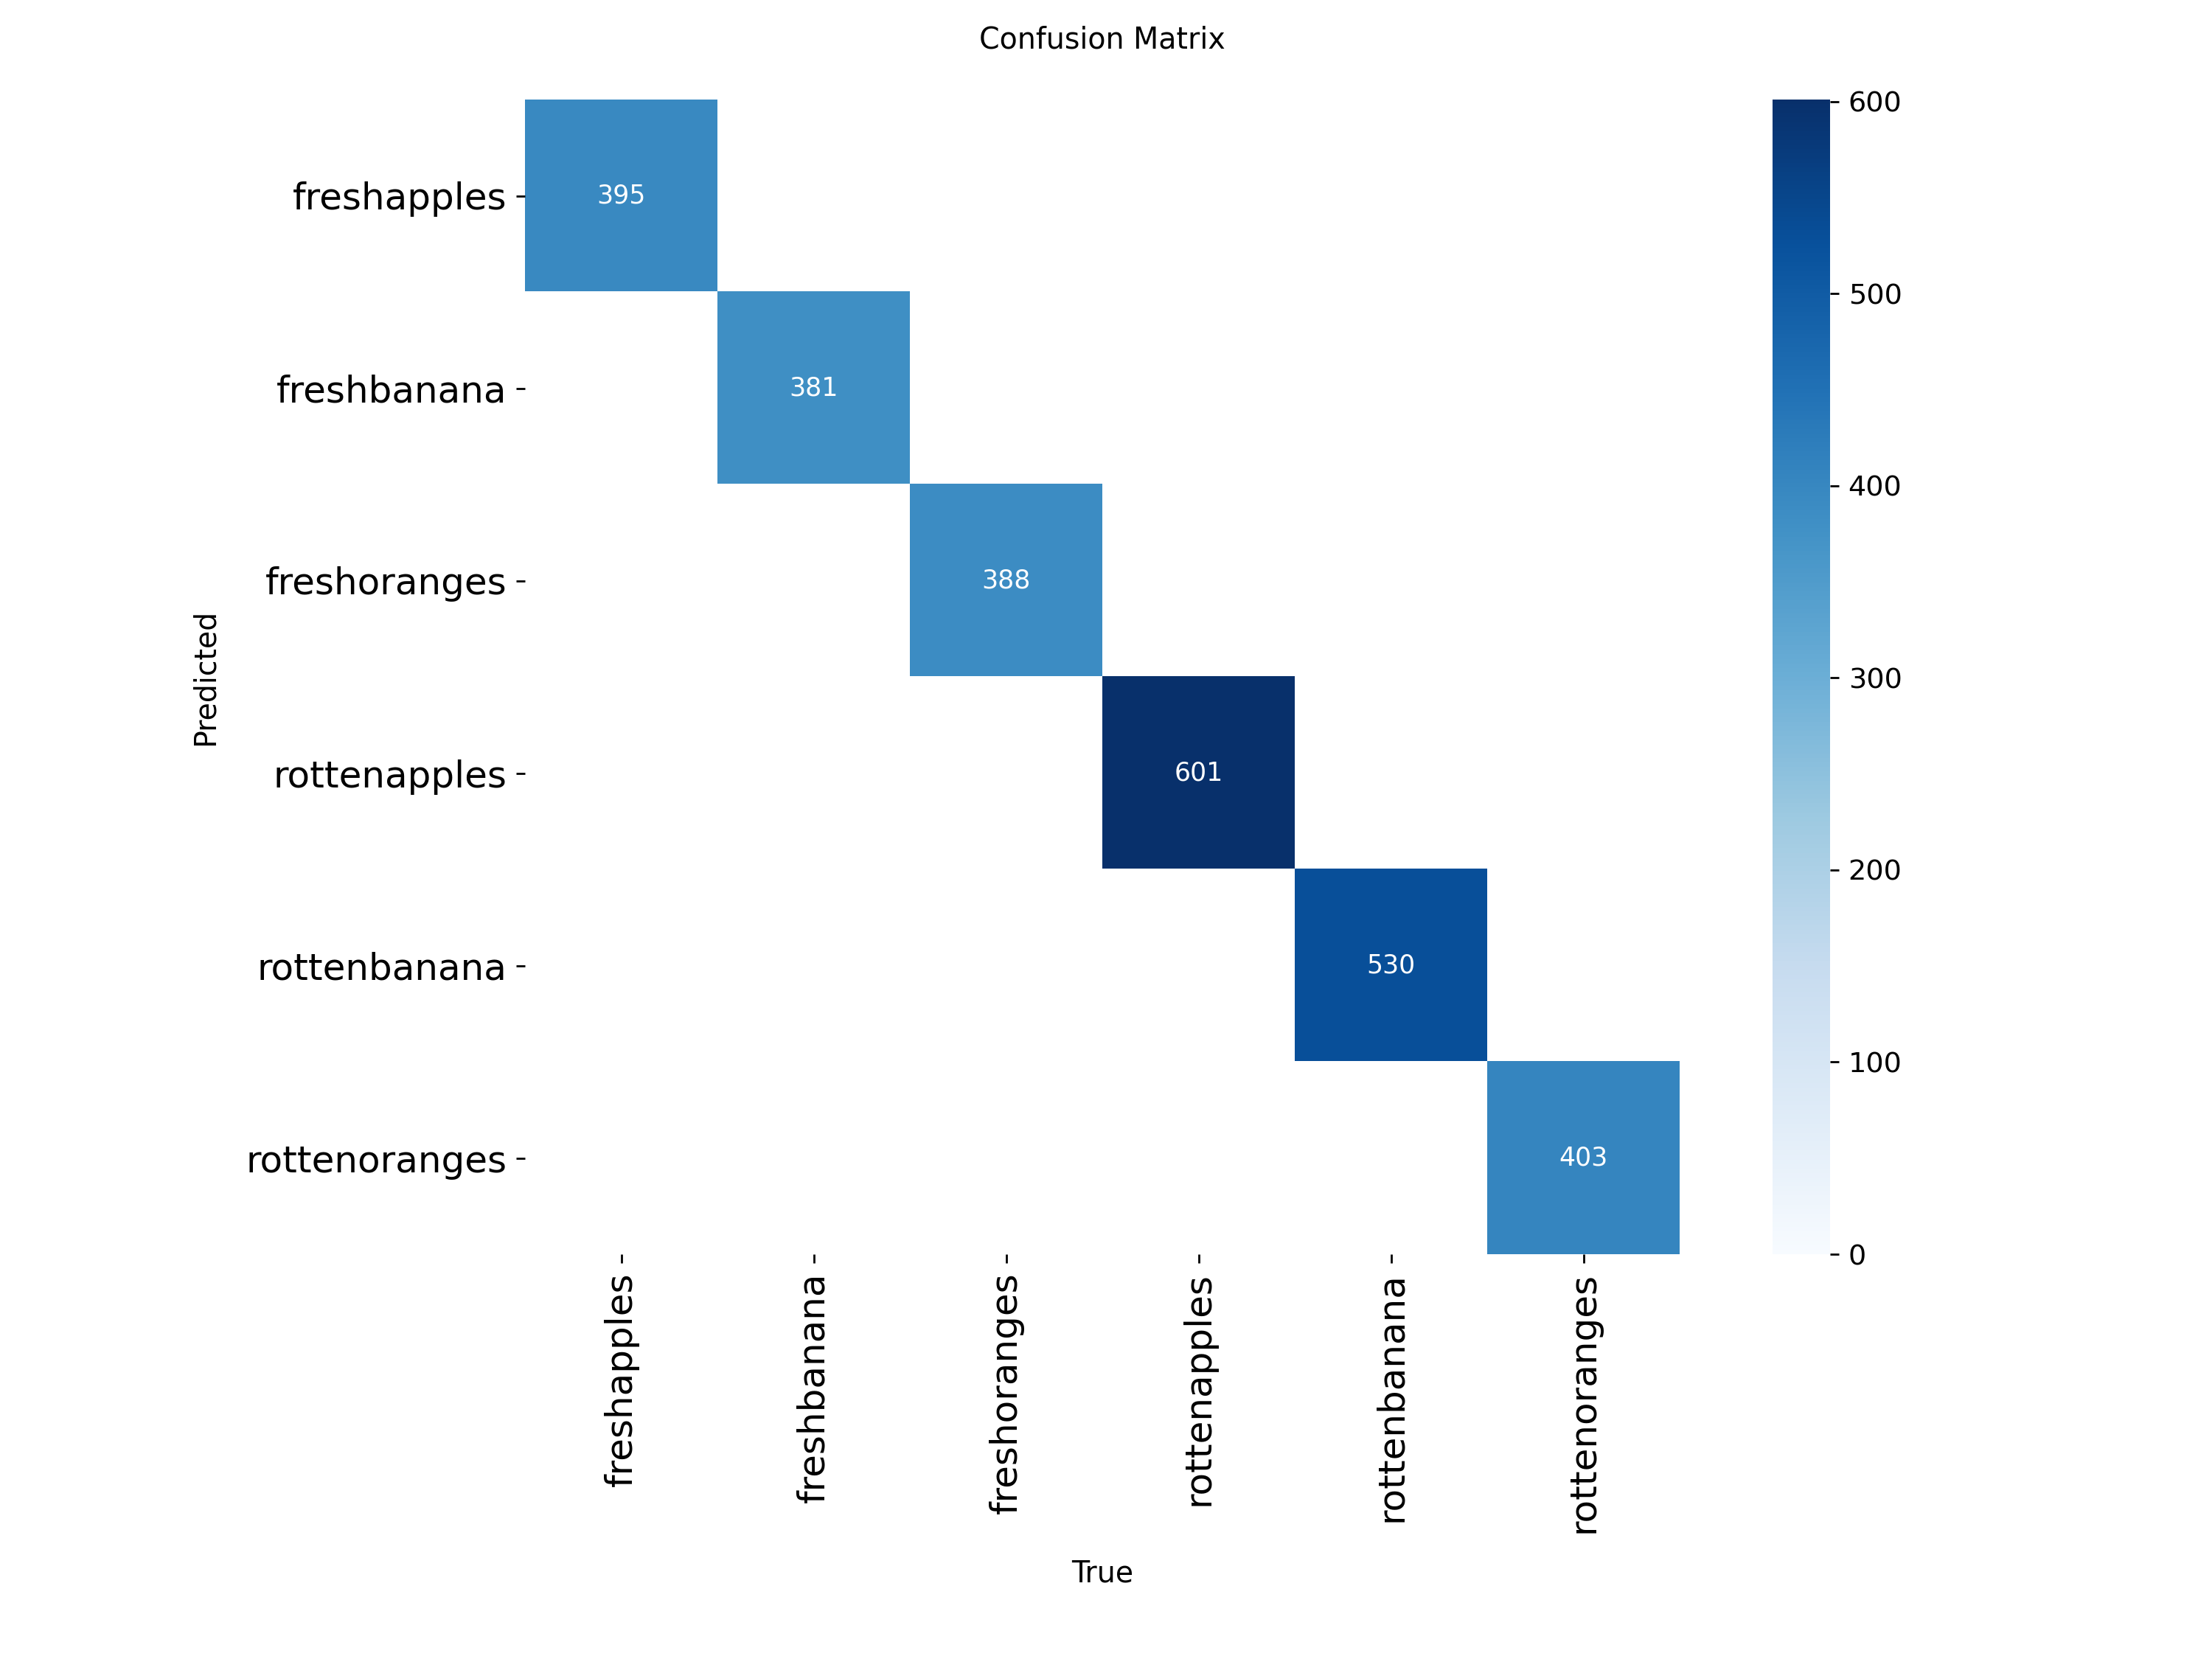

In [14]:
# --------------------------------
# Training Charts + Confusion Matrix
# --------------------------------

from IPython.display import Image, display

display(Image(f'{SAVE_DIR}/yolo_cls/results.png'))             # loss and accuracy for every epoch
display(Image(f'{SAVE_DIR}/yolo_cls/confusion_matrix.png'))    # which classes the model mixes up

# **4. TEST OUR BEST AI MODEL**

Upload one or more images of fruit:


Saving images.jpeg to images.jpeg


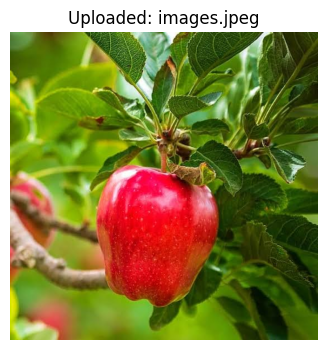

Prediction: freshapples (99.76%)
Recommended: 🧺 Keep it
Tip: This apples is fresh. Eat it or store it in the fridge.
----------------------------------------


In [16]:
# ----------------------------------------
# Required Imports
# ----------------------------------------

from ultralytics import YOLO
from google.colab import files
from PIL import Image as PILImage
import io
import matplotlib.pyplot as plt

# ----------------------------------------
# Load Best Model
# ----------------------------------------

model = YOLO('/content/drive/MyDrive/freshscan/yolo_cls/weights/best.pt')

# ----------------------------------------
# Recommendation Engine
# ----------------------------------------

def recommend(class_name):
    fruit = class_name.replace('fresh', '').replace('rotten', '').rstrip('s')   # 'rottenapples' → 'apple'
    if 'rotten' in class_name:
        return '🗑️ Compost bin', f'This {fruit} is rotten. Put it in the organic/compost bin.'
    return '🧺 Keep it', f'This {fruit} is fresh. Eat it or store it in the fridge.'

# ----------------------------------------
# Upload & Predict
# ----------------------------------------

print("Upload one or more images of fruit:")
uploaded = files.upload()

for image_name in uploaded.keys():
    image = PILImage.open(io.BytesIO(uploaded[image_name])).convert('RGB')

    # Display image
    plt.figure(figsize=(4, 4))
    plt.imshow(image)
    plt.axis('off')
    plt.title(f'Uploaded: {image_name}')
    plt.show()

    # Predict
    result = model(image, verbose=False)[0]
    label = result.names[result.probs.top1]
    confidence = result.probs.top1conf.item() * 100
    bin_name, tip = recommend(label)

    print(f"Prediction: {label} ({confidence:.2f}%)")
    print(f"Recommended: {bin_name}")
    print(f"Tip: {tip}")
    print('-' * 40)